# Practo Doctor Consultation Fee Analysis — Exploratory Data Analysis

**Notebook:** `03_exploratory_data_analysis.ipynb`  
**Stage:** Exploratory Data Analysis (EDA)

### Objective
Explore the consultation-fee landscape and identify meaningful pricing patterns across:

- overall fee distribution
- cities and city tiers
- medical specializations
- doctor experience
- patient ratings
- city × specialization combinations
- premium pricing
- fee segmentation

### Analytical principle
The analysis-ready dataset is used as the canonical input. Outliers identified during cleaning were **retained** in the project data. Where useful, a separate outlier-excluded view is created **only for sensitivity analysis**; it does not overwrite or replace the canonical dataset.

> **Important:** Observational relationships in this notebook describe patterns in this dataset. Correlation does not establish causation.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

## 2. Load the Analysis-Ready Dataset

In [2]:
df = pd.read_csv("../data/processed/practo_analysis_data.csv")

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (1080, 9)


,Doctor_Name,Specialization,Experience,Hospital_Name,City,City_Tier,Patient_Rating(%),Source,Consultation_Fee(₹)
0,Dr. Anil Krishna Gundala,Cardiologist,23,Medicover Hospitals,Hyderabad,Metro,96.00,Practo,800
1,Dr. Sai Ravi Shanker A,Cardiologist,31,Aster Prime Hospital,Hyderabad,Metro,60.00,Practo,800
2,Dr. R. Balaji,Cardiologist,37,Medicover Hospitals,Hyderabad,Metro,97.00,Practo,900
3,Dr. Krishna Prasad A R,Cardiologist,32,Medicover Hospitals,Hyderabad,Metro,82.00,Practo,800
4,Dr. Shiva Prasad Koyalakonda,Cardiologist,23,One Cardiac Centre,Hyderabad,Metro,93.00,Practo,700


### Dataset contract

This notebook expects the output of `02_data_cleaning.ipynb`:

`data/processed/practo_analysis_data.csv`

Expected columns:

`Doctor_Name`, `Specialization`, `Experience`, `Hospital_Name`, `City`, `City_Tier`, `Patient_Rating(%)`, `Source`, `Consultation_Fee(₹)`

## 3. Initial Data Audit

In [3]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1080, 9)

Data types:


Doctor_Name             object
Specialization          object
Experience               int64
Hospital_Name           object
City                    object
City_Tier               object
Patient_Rating(%)      float64
Source                  object
Consultation_Fee(₹)      int64
dtype: object


Missing values:


Doctor_Name            0
Specialization         0
Experience             0
Hospital_Name          0
City                   0
City_Tier              0
Patient_Rating(%)      0
Source                 0
Consultation_Fee(₹)    0
dtype: int64


Duplicate rows: 0


In [4]:
print("Unique specializations:", df["Specialization"].nunique())
print("Unique cities:", df["City"].nunique())
print("City tiers:", df["City_Tier"].unique().tolist())
print("Sources:", df["Source"].unique().tolist())

Unique specializations: 9
Unique cities: 12
City tiers: ['Metro', 'Non-Metro']
Sources: ['Practo']


### Analysis views used in this notebook

| View | Purpose |
|---|---|
| `df` | Canonical analysis dataset; outliers retained |
| `df_no_fee_outliers` | Sensitivity analysis after excluding consultation-fee IQR outliers |
| `df_paid` | Analysis of paid consultations only (`fee > 0`) |
| `df_paid_no_outliers` | Paid consultations after fee-outlier exclusion |

This distinction prevents accidental mixing of different analytical populations.

In [5]:
Q1_fee = df["Consultation_Fee(₹)"].quantile(0.25)
Q3_fee = df["Consultation_Fee(₹)"].quantile(0.75)
IQR_fee = Q3_fee - Q1_fee
lower_fee_bound = Q1_fee - 1.5 * IQR_fee
upper_fee_bound = Q3_fee + 1.5 * IQR_fee

df_no_fee_outliers = df[
    df["Consultation_Fee(₹)"].between(lower_fee_bound, upper_fee_bound)
].copy()

df_paid = df[df["Consultation_Fee(₹)"] > 0].copy()
df_paid_no_outliers = df_no_fee_outliers[
    df_no_fee_outliers["Consultation_Fee(₹)"] > 0
].copy()

print(f"Fee Q1: ₹{Q1_fee:,.0f}")
print(f"Fee Q3: ₹{Q3_fee:,.0f}")
print(f"Fee IQR: ₹{IQR_fee:,.0f}")
print(f"Lower IQR bound: ₹{lower_fee_bound:,.0f}")
print(f"Upper IQR bound: ₹{upper_fee_bound:,.0f}")
print(f"Fee outliers excluded for sensitivity analysis: {len(df) - len(df_no_fee_outliers)}")

Fee Q1: ₹500
Fee Q3: ₹1,000
Fee IQR: ₹500
Lower IQR bound: ₹-250
Upper IQR bound: ₹1,750
Fee outliers excluded for sensitivity analysis: 39


## 4. Overall Consultation-Fee Landscape

We begin with descriptive statistics using the **canonical dataset (`df`)**, because the project intentionally retains genuine high-fee observations.

In [6]:
fee_stats = pd.Series({
    "Average Fee": df["Consultation_Fee(₹)"].mean(),
    "Median Fee": df["Consultation_Fee(₹)"].median(),
    "Minimum Fee": df["Consultation_Fee(₹)"].min(),
    "Maximum Fee": df["Consultation_Fee(₹)"].max(),
    "Std Deviation": df["Consultation_Fee(₹)"].std(),
    "Total Doctors": df["Consultation_Fee(₹)"].count(),
    "Free Consultations": (df["Consultation_Fee(₹)"] == 0).sum()
}).to_frame("Value")

fee_stats

,Value
Average Fee,829.35
Median Fee,800.00
Minimum Fee,0.00
Maximum Fee,"4,000.00"
Std Deviation,434.86
Total Doctors,"1,080.00"
Free Consultations,27.00


### 4.1 Distribution of Consultation Fees

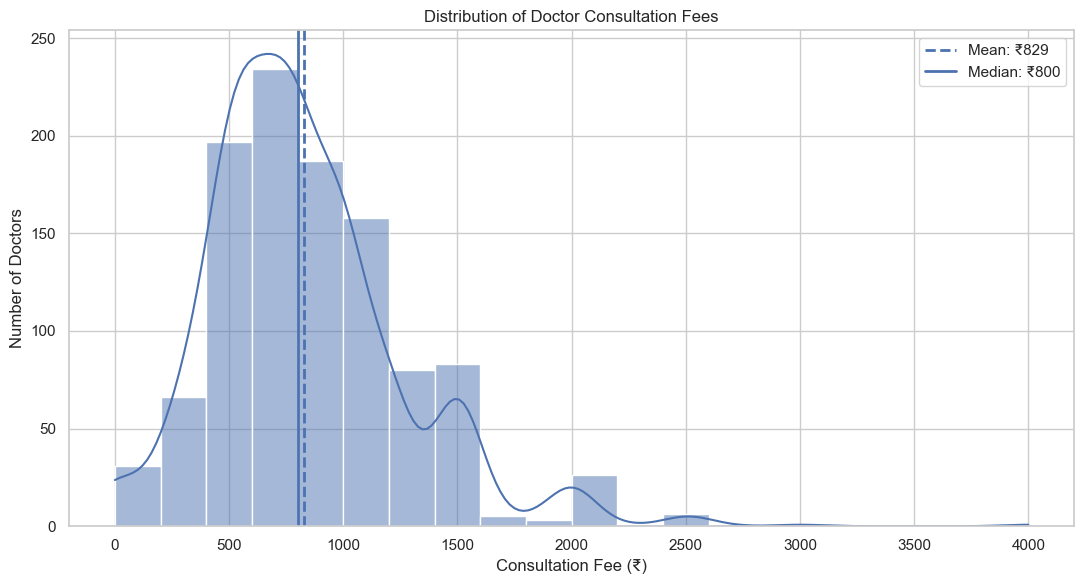

In [7]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="Consultation_Fee(₹)",
    bins=20,
    kde=True
)

plt.axvline(
    df["Consultation_Fee(₹)"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: ₹{df['Consultation_Fee(₹)'].mean():,.0f}"
)

plt.axvline(
    df["Consultation_Fee(₹)"].median(),
    linestyle="-",
    linewidth=2,
    label=f"Median: ₹{df['Consultation_Fee(₹)'].median():,.0f}"
)

plt.title("Distribution of Doctor Consultation Fees")
plt.xlabel("Consultation Fee (₹)")
plt.ylabel("Number of Doctors")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
mean_fee = df["Consultation_Fee(₹)"].mean()
median_fee = df["Consultation_Fee(₹)"].median()

print(f"Mean fee: ₹{mean_fee:,.2f}")
print(f"Median fee: ₹{median_fee:,.2f}")
print(f"Mean - Median: ₹{mean_fee - median_fee:,.2f}")

Mean fee: ₹829.35
Median fee: ₹800.00
Mean - Median: ₹29.35


**Interpretation:** A mean above the median indicates that higher-fee observations are pulling the average upward. This is a distributional observation, not evidence that premium doctors cause the higher average.

### 4.2 Fee Outlier Sensitivity Analysis

In [9]:
comparison_fee = pd.DataFrame({
    "Scenario": [
        "Canonical dataset (outliers retained)",
        "Sensitivity view (fee outliers excluded)"
    ],
    "Doctors": [
        len(df),
        len(df_no_fee_outliers)
    ],
    "Average Fee (₹)": [
        df["Consultation_Fee(₹)"].mean(),
        df_no_fee_outliers["Consultation_Fee(₹)"].mean()
    ],
    "Median Fee (₹)": [
        df["Consultation_Fee(₹)"].median(),
        df_no_fee_outliers["Consultation_Fee(₹)"].median()
    ]
})

comparison_fee.round(2)

,Scenario,Doctors,Average Fee (₹),Median Fee (₹)
0,Canonical dataset (outliers retained),1080,829.35,800.00
1,Sensitivity view (fee outliers excluded),1041,779.54,750.00


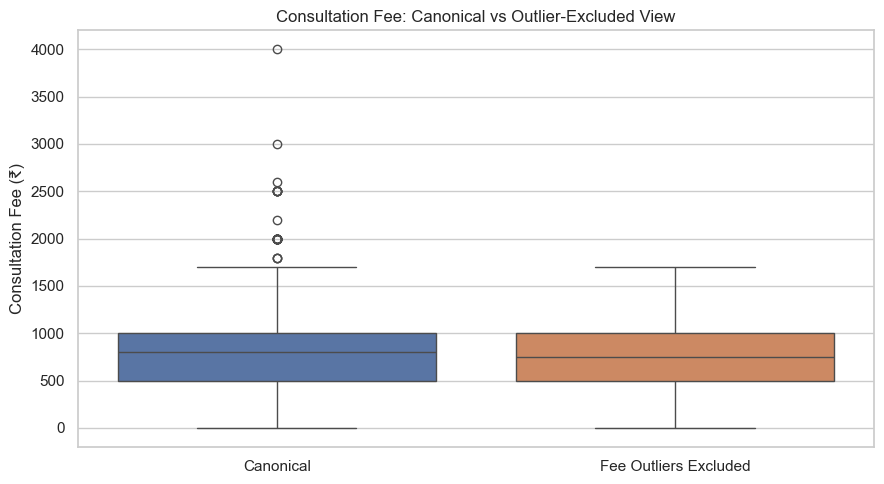

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=pd.DataFrame({
        "Canonical": df["Consultation_Fee(₹)"],
        "Fee Outliers Excluded": df_no_fee_outliers["Consultation_Fee(₹)"]
    })
)

plt.title("Consultation Fee: Canonical vs Outlier-Excluded View")
plt.ylabel("Consultation Fee (₹)")
plt.tight_layout()
plt.show()

**Methodological note:** The outlier-excluded view is a sensitivity check. We do **not** claim that the filtered data is the “real” market and we do not remove high-fee observations from the canonical dataset.

## 5. City-Wise Pricing Analysis

In [11]:
city_fee_stats = (
    df.groupby("City")["Consultation_Fee(₹)"]
      .agg(
          Average_Fee="mean",
          Median_Fee="median",
          Std_Deviation="std",
          Min_Fee="min",
          Max_Fee="max",
          Doctors="count"
      )
      .sort_values("Average_Fee", ascending=False)
      .round(2)
)

city_fee_stats

,Average_Fee,Median_Fee,Std_Deviation,Min_Fee,Max_Fee,Doctors
City,,,,,,
Mumbai,"1,478.89","1,500.00",602.15,500,4000,90
Delhi,"1,054.44","1,000.00",399.48,300,3000,90
Kolkata,"1,005.00",950.00,389.18,300,2500,90
Pune,879.42,825.00,356.52,0,2000,90
Bangalore,852.22,800.00,297.36,300,1500,90
Ahmedabad,822.22,800.00,402.67,0,2200,90
Chandigarh,723.89,700.00,402.75,0,2500,90
Chennai,716.67,750.00,284.92,0,1500,90
Hyderabad,705.00,700.00,222.61,0,1500,90


In [12]:
most_expensive_city = city_fee_stats["Average_Fee"].idxmax()
most_affordable_city = city_fee_stats["Average_Fee"].idxmin()

print(f"Highest average consultation fee: {most_expensive_city}")
print(f"Lowest average consultation fee: {most_affordable_city}")

Highest average consultation fee: Mumbai
Lowest average consultation fee: Patna


### 5.1 Average Consultation Fee by City

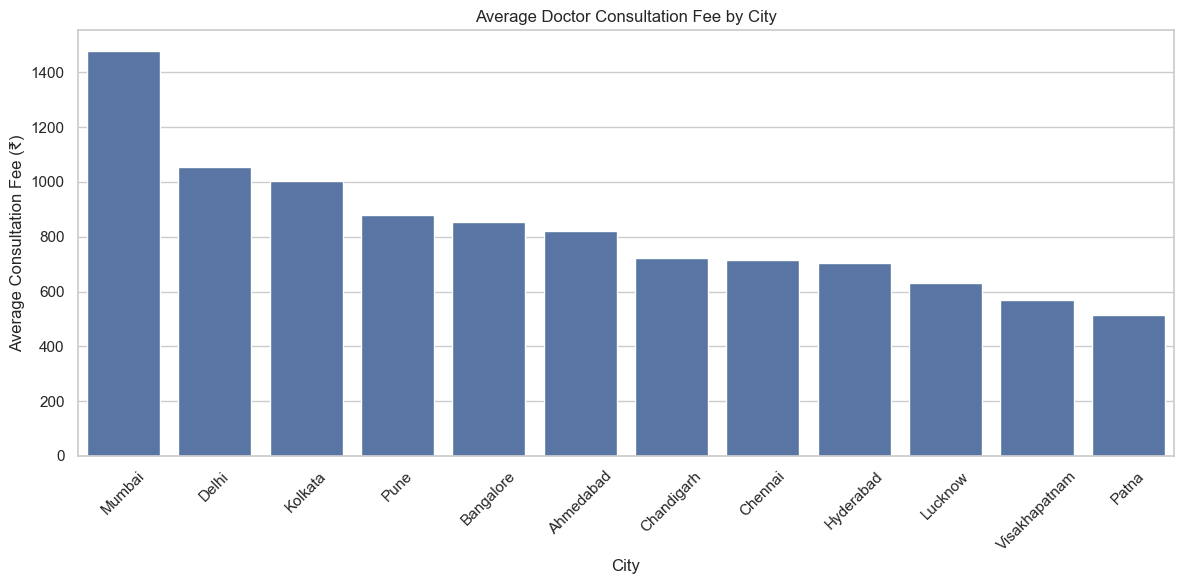

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=city_fee_stats.reset_index(),
    x="City",
    y="Average_Fee",
    order=city_fee_stats.index
)

plt.title("Average Doctor Consultation Fee by City")
plt.xlabel("City")
plt.ylabel("Average Consultation Fee (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.2 Fee Distribution Across Cities

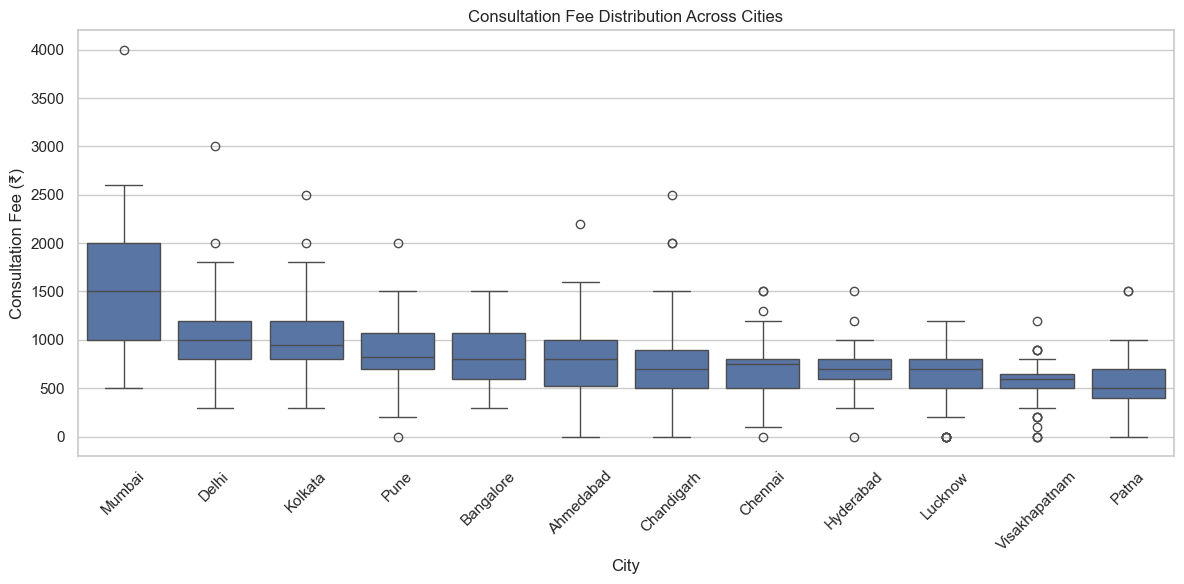

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="City",
    y="Consultation_Fee(₹)",
    order=city_fee_stats.index
)

plt.title("Consultation Fee Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Consultation Fee (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.3 Metro vs Non-Metro Pricing

In [15]:
tier_fee = (
    df.groupby("City_Tier")["Consultation_Fee(₹)"]
      .agg(
          Average_Fee="mean",
          Median_Fee="median",
          Std_Deviation="std",
          Doctors="count"
      )
      .round(2)
)

tier_fee

,Average_Fee,Median_Fee,Std_Deviation,Doctors
City_Tier,,,,
Metro,968.70,900.00,465.63,540
Non-Metro,690.00,700.00,350.48,540


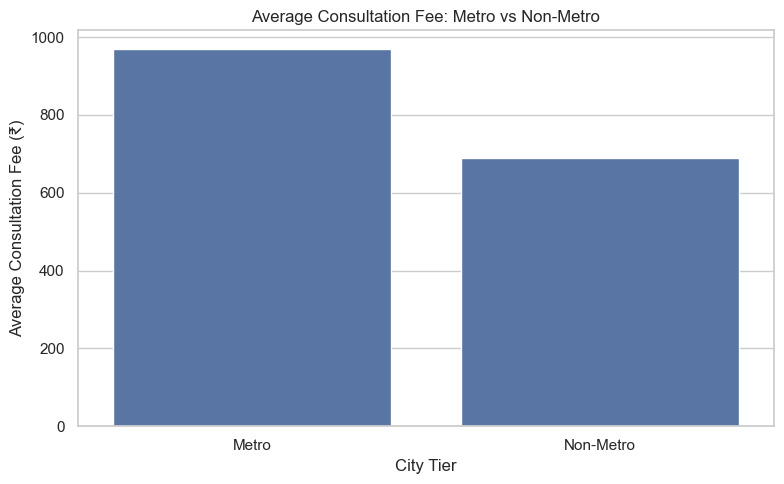

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="City_Tier",
    y="Consultation_Fee(₹)",
    estimator="mean",
    errorbar=None
)

plt.title("Average Consultation Fee: Metro vs Non-Metro")
plt.xlabel("City Tier")
plt.ylabel("Average Consultation Fee (₹)")
plt.tight_layout()
plt.show()

In [17]:
metro_mean = tier_fee.loc["Metro", "Average_Fee"]
non_metro_mean = tier_fee.loc["Non-Metro", "Average_Fee"]

print(f"Metro average fee: ₹{metro_mean:,.2f}")
print(f"Non-Metro average fee: ₹{non_metro_mean:,.2f}")
print(f"Difference: ₹{metro_mean - non_metro_mean:,.2f}")

Metro average fee: ₹968.70
Non-Metro average fee: ₹690.00
Difference: ₹278.70


**Interpretation:** If Metro fees are higher in this dataset, this indicates an observed association between city tier and consultation pricing. It should not be described as proof that being a metro city causes higher fees.

## 6. Specialization-Wise Pricing Analysis

In [18]:
spec_fee_stats = (
    df.groupby("Specialization")["Consultation_Fee(₹)"]
      .agg(
          Average_Fee="mean",
          Median_Fee="median",
          Std_Deviation="std",
          Min_Fee="min",
          Max_Fee="max",
          Doctors="count"
      )
      .sort_values("Average_Fee", ascending=False)
      .round(2)
)

spec_fee_stats

,Average_Fee,Median_Fee,Std_Deviation,Min_Fee,Max_Fee,Doctors
Specialization,,,,,,
Cardiologist,"1,016.25",975.00,443.68,0,2500,120
Neurologist,991.25,"1,000.00",487.91,0,2500,120
General Surgeon,866.67,800.00,497.66,0,4000,120
Orthopedist,859.58,700.00,447.74,0,2600,120
General Physician,858.75,800.00,395.76,0,2500,120
Dermatologist,839.58,800.00,333.80,0,2000,120
ENT,814.17,800.00,415.26,0,3000,120
Gynecologist,792.50,700.00,342.24,0,2000,120
Dentist,425.40,400.00,207.04,0,1500,120


### 6.1 Average Fee by Specialization

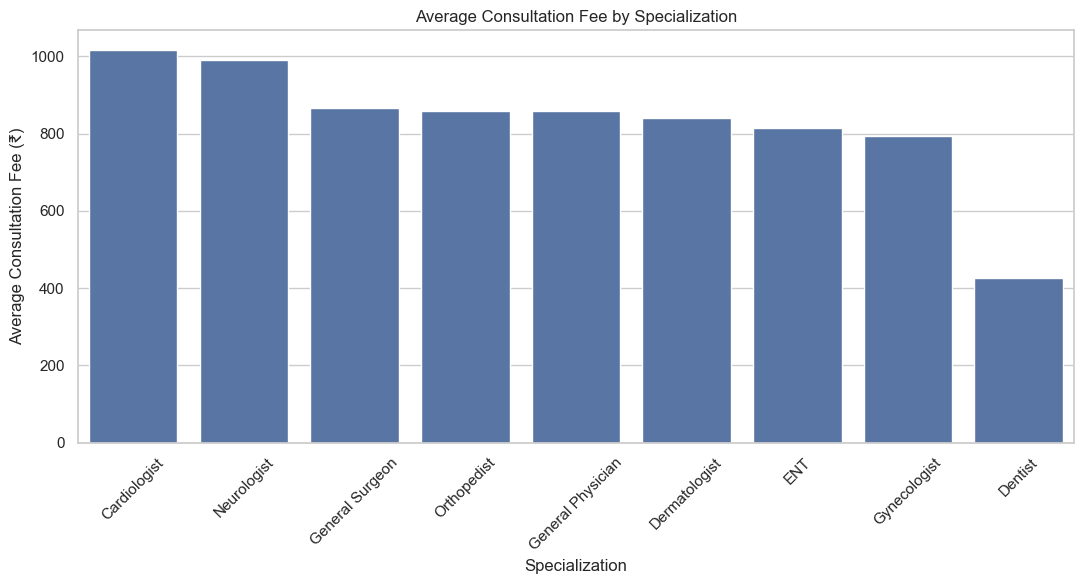

In [19]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=spec_fee_stats.reset_index(),
    x="Specialization",
    y="Average_Fee",
    order=spec_fee_stats.index
)

plt.title("Average Consultation Fee by Specialization")
plt.xlabel("Specialization")
plt.ylabel("Average Consultation Fee (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Fee Distribution by Specialization

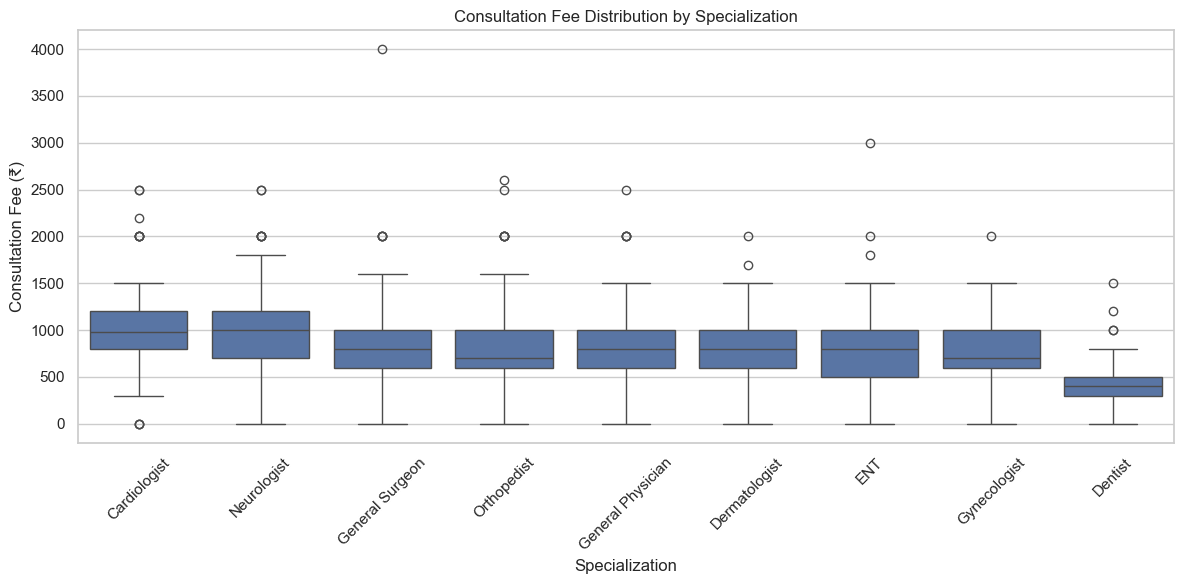

In [20]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Specialization",
    y="Consultation_Fee(₹)",
    order=spec_fee_stats.index
)

plt.title("Consultation Fee Distribution by Specialization")
plt.xlabel("Specialization")
plt.ylabel("Consultation Fee (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.3 Paid-Only Pricing Comparison

In [21]:
spec_paid_stats = (
    df_paid.groupby("Specialization")["Consultation_Fee(₹)"]
           .agg(
               Average_Fee="mean",
               Median_Fee="median",
               Std_Deviation="std",
               Doctors="count"
           )
           .sort_values("Average_Fee", ascending=False)
           .round(2)
)

spec_paid_stats

,Average_Fee,Median_Fee,Std_Deviation,Doctors
Specialization,,,,
Neurologist,"1,052.65","1,000.00",433.26,113
Cardiologist,"1,042.31","1,000.00",417.79,117
General Surgeon,896.55,800.00,478.80,116
Orthopedist,866.81,700.00,442.56,119
General Physician,865.97,800.00,389.42,119
Dermatologist,853.81,800.00,317.92,118
ENT,827.97,800.00,404.81,118
Gynecologist,819.83,700.00,314.01,116
Dentist,436.31,400.00,197.92,117


In [22]:
spec_paid_comparison = pd.concat(
    [
        spec_fee_stats["Average_Fee"].rename("Including Free Consultations"),
        spec_paid_stats["Average_Fee"].rename("Paid Only")
    ],
    axis=1
).round(2)

spec_paid_comparison

,Including Free Consultations,Paid Only
Specialization,,
Cardiologist,"1,016.25","1,042.31"
Neurologist,991.25,"1,052.65"
General Surgeon,866.67,896.55
Orthopedist,859.58,866.81
General Physician,858.75,865.97
Dermatologist,839.58,853.81
ENT,814.17,827.97
Gynecologist,792.50,819.83
Dentist,425.40,436.31


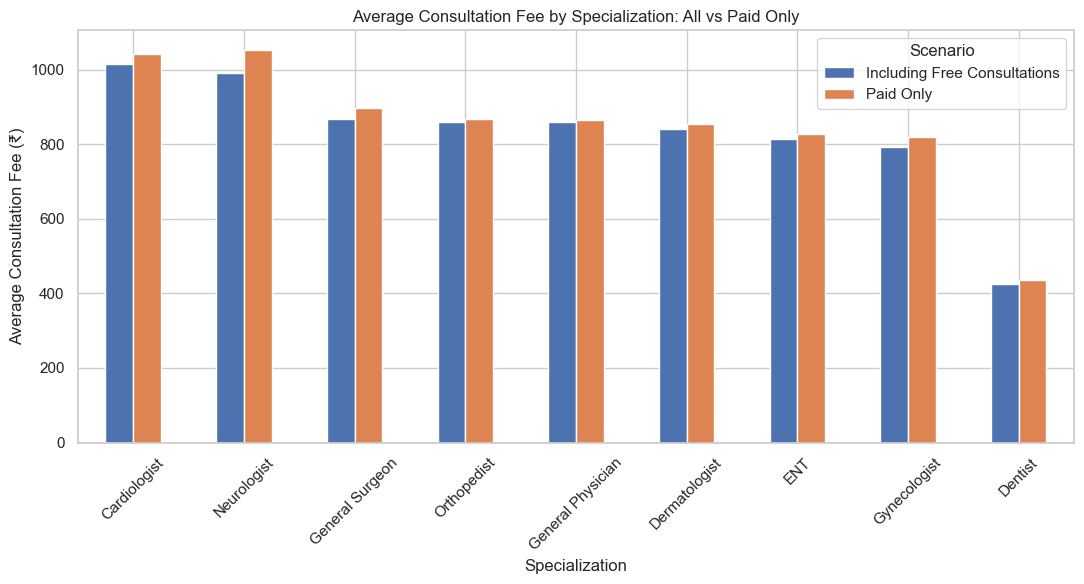

In [23]:
spec_paid_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Average Consultation Fee by Specialization: All vs Paid Only")
plt.xlabel("Specialization")
plt.ylabel("Average Consultation Fee (₹)")
plt.xticks(rotation=45)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()

**Why paid-only analysis?** Converting `Free Consultation` to ₹0 is appropriate for preserving the economic meaning of the original field. However, zero-fee records can lower average prices. The paid-only view therefore acts as a secondary sensitivity analysis rather than replacing the canonical analysis.

### 6.4 Fee Variability by Specialization

In [24]:
spec_variability = (
    df_paid.groupby("Specialization")["Consultation_Fee(₹)"]
           .agg(
               Variance="var",
               Std_Deviation="std",
               Fee_Range=lambda s: s.max() - s.min()
           )
           .sort_values("Variance", ascending=False)
           .round(2)
)

spec_variability

,Variance,Std_Deviation,Fee_Range
Specialization,,,
General Surgeon,"229,248.88",478.80,3800
Orthopedist,"195,859.21",442.56,2300
Neurologist,"187,716.10",433.26,2200
Cardiologist,"174,552.39",417.79,2200
ENT,"163,869.33",404.81,2800
General Physician,"151,649.69",389.42,2300
Dermatologist,"101,075.08",317.92,1700
Gynecologist,"98,603.45",314.01,1700
Dentist,"39,172.99",197.92,1400


**Interpretation:** Higher variance or standard deviation means fees are more dispersed within that specialization. It does not by itself explain *why* the dispersion exists.

## 7. Experience vs Consultation Fee

In [25]:
experience_fee_corr = df[["Experience", "Consultation_Fee(₹)"]].corr().loc[
    "Experience", "Consultation_Fee(₹)"
]

print(f"Pearson correlation: {experience_fee_corr:.3f}")

Pearson correlation: 0.142


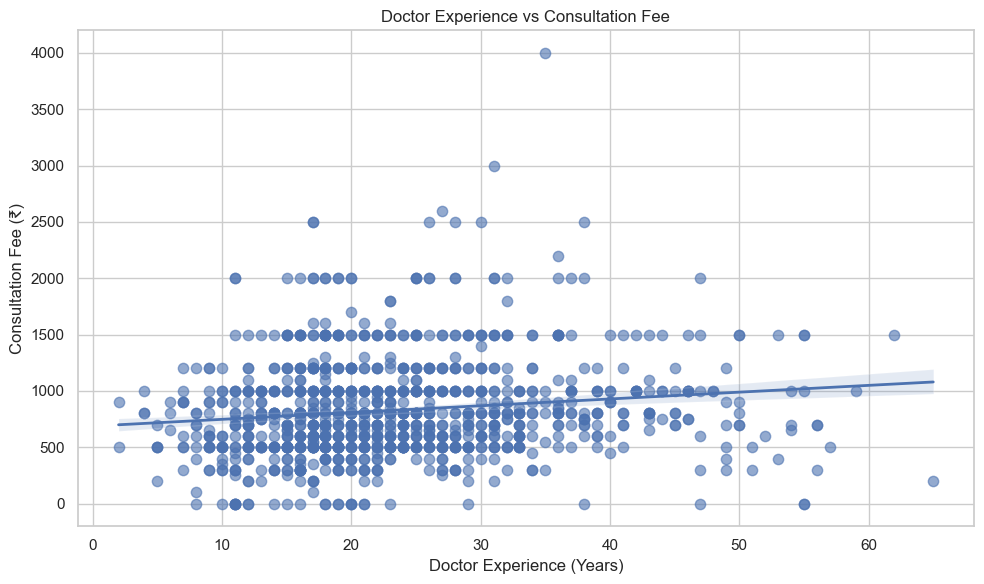

In [26]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Experience",
    y="Consultation_Fee(₹)",
    scatter_kws={"alpha": 0.6, "s": 55},
    line_kws={"linewidth": 2}
)

plt.title("Doctor Experience vs Consultation Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Consultation Fee (₹)")
plt.tight_layout()
plt.show()

### Interpretation

A weak positive correlation means that experience and consultation fee move together only modestly in this dataset. The wide vertical spread at similar experience levels indicates that experience alone does not explain consultation pricing.

The regression line summarizes an association; it does **not** establish a causal effect of experience on fees.

## 8. Patient Rating vs Consultation Fee

In [27]:
rating_fee_corr = df[["Patient_Rating(%)", "Consultation_Fee(₹)"]].corr().loc[
    "Patient_Rating(%)", "Consultation_Fee(₹)"
]

print(f"Pearson correlation: {rating_fee_corr:.3f}")

Pearson correlation: -0.133


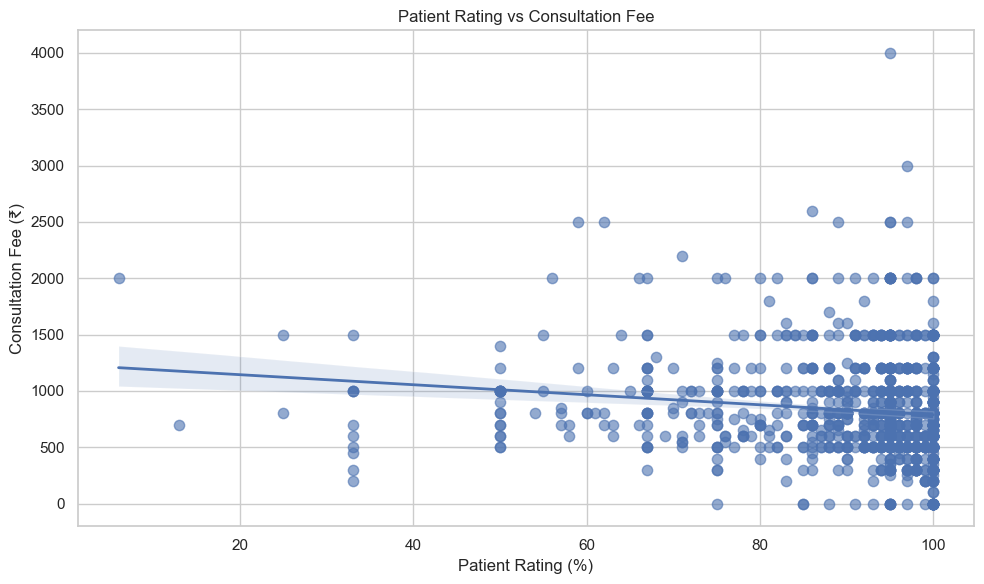

In [28]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Patient_Rating(%)",
    y="Consultation_Fee(₹)",
    scatter_kws={"alpha": 0.6, "s": 55},
    line_kws={"linewidth": 2}
)

plt.title("Patient Rating vs Consultation Fee")
plt.xlabel("Patient Rating (%)")
plt.ylabel("Consultation Fee (₹)")
plt.tight_layout()
plt.show()

### Interpretation

A weak correlation indicates that patient rating has limited linear association with consultation fee in this dataset. High-rated doctors can still appear across a wide range of prices.

This analysis does not support a causal statement that ratings increase or decrease consultation fees.

## 9. Correlation Overview

In [29]:
corr_columns = [
    "Experience",
    "Patient_Rating(%)",
    "Consultation_Fee(₹)"
]

corr_table = df[corr_columns].corr().round(2)
corr_table

,Experience,Patient_Rating(%),Consultation_Fee(₹)
Experience,1.00,-0.18,0.14
Patient_Rating(%),-0.18,1.00,-0.13
Consultation_Fee(₹),0.14,-0.13,1.00


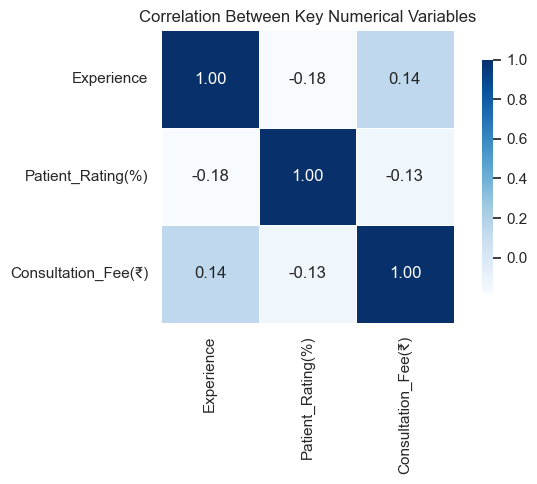

In [30]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_table,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Between Key Numerical Variables")
plt.tight_layout()
plt.show()

### Correlation takeaway

Correlation is useful for identifying the strength and direction of linear association. It is **not** a measure of causality and does not account for all other factors that may influence consultation fees.

## 10. City × Specialization Pricing

In [31]:
city_spec_pivot = pd.pivot_table(
    data=df,
    values="Consultation_Fee(₹)",
    index="City",
    columns="Specialization",
    aggfunc="mean"
)

city_spec_pivot

Specialization,Cardiologist,Dentist,Dermatologist,ENT,General Physician,General Surgeon,Gynecologist,Neurologist,Orthopedist
City,,,,,,,,,
Ahmedabad,"1,380.00",370.00,785.00,585.00,880.00,990.00,730.00,930.00,750.00
Bangalore,"1,080.00",440.00,835.00,890.00,925.00,905.00,655.00,"1,120.00",820.00
Chandigarh,920.00,490.00,690.00,680.00,560.00,630.00,900.00,"1,000.00",645.00
Chennai,860.00,315.00,870.00,740.00,815.00,835.00,540.00,870.00,605.00
Delhi,"1,120.00",560.00,"1,250.00","1,250.00","1,070.00",900.00,"1,070.00","1,220.00","1,050.00"
Hyderabad,825.00,380.00,785.00,820.00,705.00,655.00,660.00,810.00,705.00
Kolkata,"1,180.00",680.00,930.00,"1,100.00",800.00,"1,290.00","1,030.00","1,100.00",935.00
Lucknow,740.00,440.00,520.00,530.00,730.00,520.00,640.00,840.00,715.00
Mumbai,"1,800.00",500.00,"1,350.00","1,350.00","1,670.00","1,570.00","1,290.00","1,800.00","1,980.00"


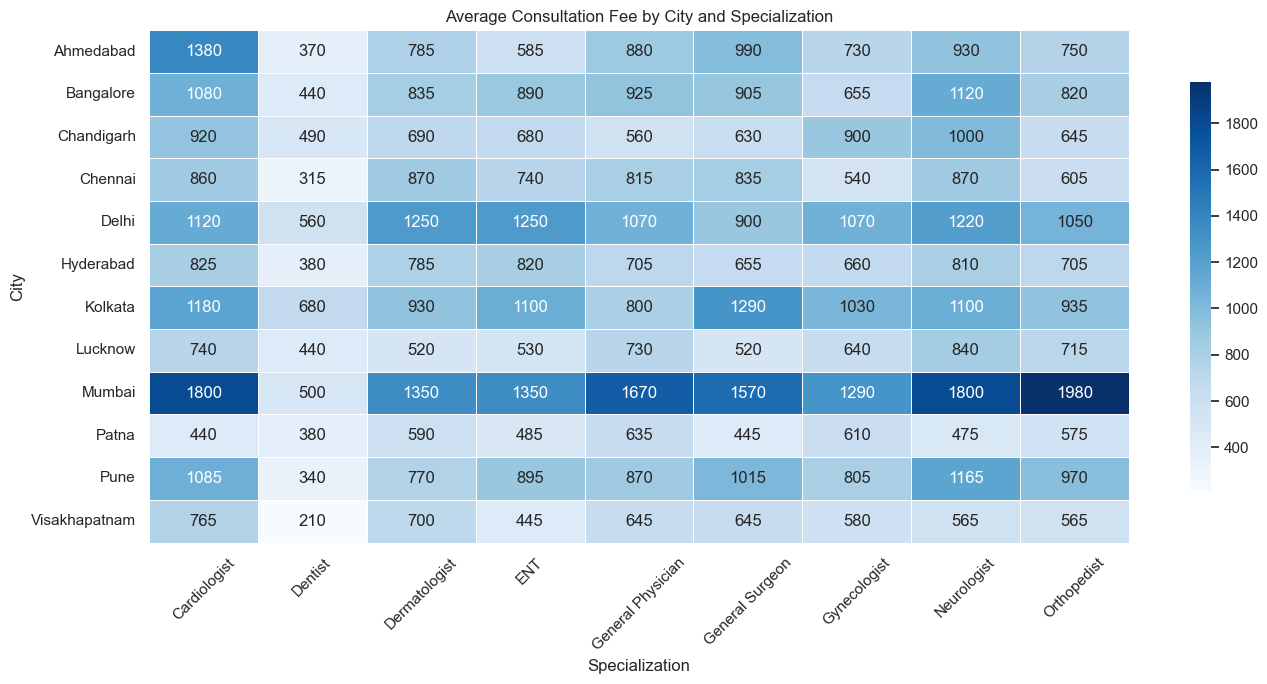

In [32]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    city_spec_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Average Consultation Fee by City and Specialization")
plt.xlabel("Specialization")
plt.ylabel("City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:** The heatmap allows the same specialization to be compared across cities and highlights city–specialization combinations with relatively high or low observed fees. These are descriptive market patterns, not causal effects.

## 11. Premium Pricing Analysis

In [33]:
premium_threshold = df["Consultation_Fee(₹)"].quantile(0.75)

premium_doctors = df[
    df["Consultation_Fee(₹)"] >= premium_threshold
].copy()

print(f"75th-percentile fee threshold: ₹{premium_threshold:,.0f}")
print(f"Records at or above threshold: {len(premium_doctors):,}")
print(f"Share of records: {len(premium_doctors) / len(df):.1%}")

75th-percentile fee threshold: ₹1,000
Records at or above threshold: 365
Share of records: 33.8%


**Definition:** The premium group consists of records whose consultation fee is at or above the 75th percentile of the canonical fee distribution.

Because percentile thresholds can coincide with repeated fee values, the resulting share may be slightly above 25%.

### 11.1 Premium Records by City

In [34]:
premium_city = (
    premium_doctors.groupby("City")
                   .size()
                   .rename("Premium_Doctors")
                   .to_frame()
)

premium_city["Total_Doctors"] = df.groupby("City").size()
premium_city["Premium_Share"] = (
    premium_city["Premium_Doctors"] / premium_city["Total_Doctors"]
)

premium_city = premium_city.sort_values("Premium_Share", ascending=False)
premium_city.round(3)

,Premium_Doctors,Total_Doctors,Premium_Share
City,,,
Mumbai,78,90,0.87
Delhi,60,90,0.67
Kolkata,45,90,0.50
Ahmedabad,38,90,0.42
Bangalore,37,90,0.41
Pune,35,90,0.39
Chennai,21,90,0.23
Chandigarh,21,90,0.23
Hyderabad,13,90,0.14


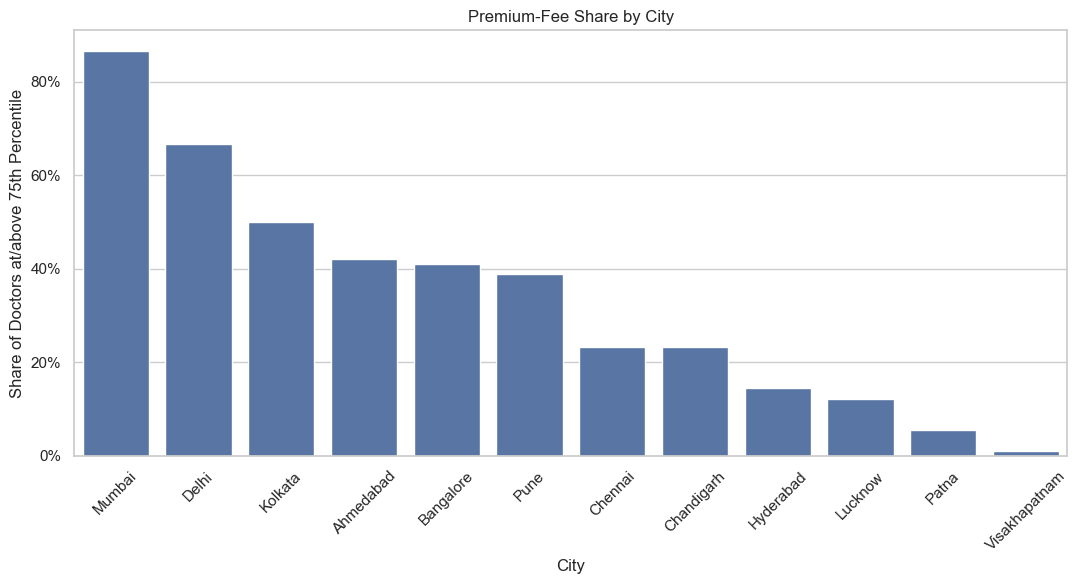

In [35]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=premium_city.reset_index(),
    x="City",
    y="Premium_Share",
    order=premium_city.index
)

plt.title("Premium-Fee Share by City")
plt.xlabel("City")
plt.ylabel("Share of Doctors at/above 75th Percentile")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
plt.tight_layout()
plt.show()

### 11.2 Premium Records by Specialization

In [36]:
premium_spec = (
    premium_doctors.groupby("Specialization")
                   .size()
                   .rename("Premium_Doctors")
                   .to_frame()
)

premium_spec["Total_Doctors"] = df.groupby("Specialization").size()
premium_spec["Premium_Share"] = (
    premium_spec["Premium_Doctors"] / premium_spec["Total_Doctors"]
)

premium_spec = premium_spec.sort_values("Premium_Share", ascending=False)

premium_spec.round(3)

,Premium_Doctors,Total_Doctors,Premium_Share
Specialization,,,
Neurologist,64,120,0.53
Cardiologist,60,120,0.50
General Physician,43,120,0.36
General Surgeon,43,120,0.36
ENT,40,120,0.33
Gynecologist,38,120,0.32
Dermatologist,37,120,0.31
Orthopedist,36,120,0.30
Dentist,4,120,0.03


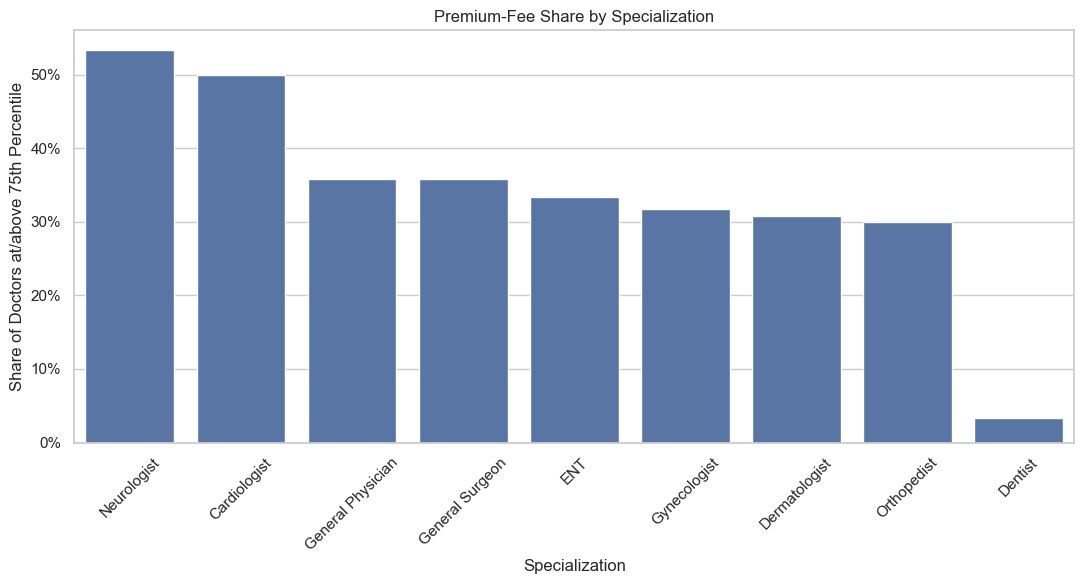

In [37]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=premium_spec.reset_index(),
    x="Specialization",
    y="Premium_Share",
    order=premium_spec.index
)

plt.title("Premium-Fee Share by Specialization")
plt.xlabel("Specialization")
plt.ylabel("Share of Doctors at/above 75th Percentile")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
plt.tight_layout()
plt.show()

### 11.3 Premium City × Specialization

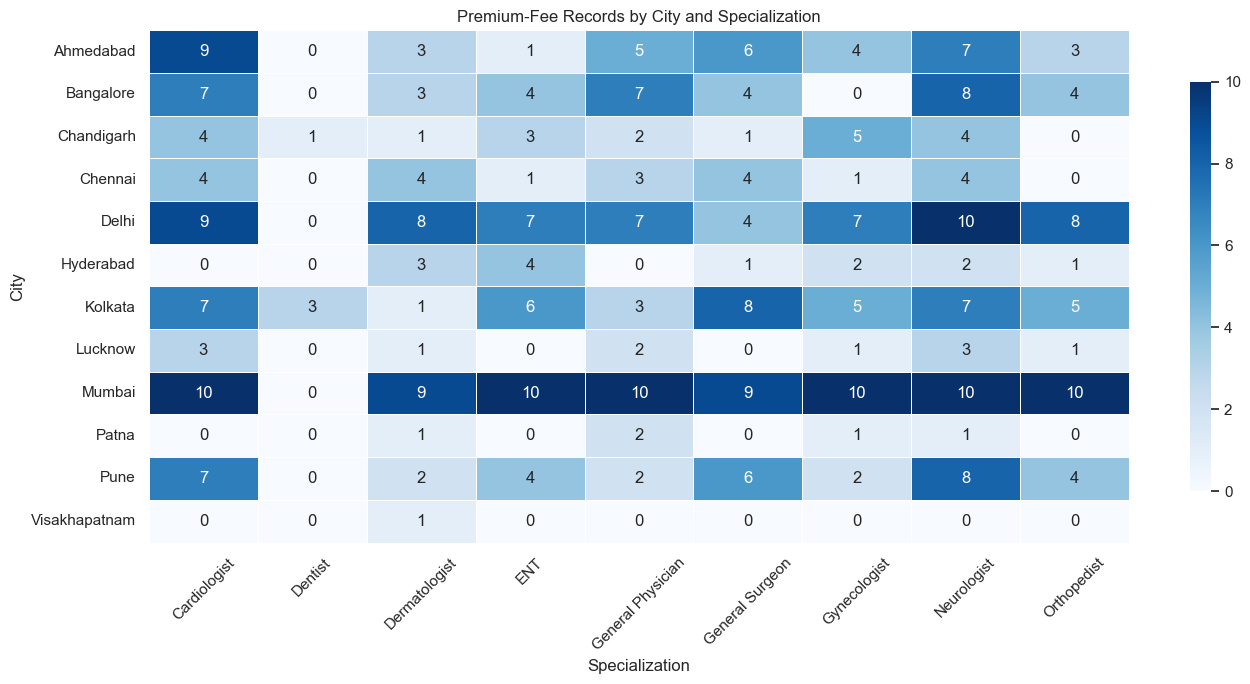

In [38]:
premium_city_spec = pd.crosstab(
    premium_doctors["City"],
    premium_doctors["Specialization"]
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    premium_city_spec,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Premium-Fee Records by City and Specialization")
plt.xlabel("Specialization")
plt.ylabel("City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Premium pricing interpretation

This section identifies where high-fee observations are concentrated. A high premium share can indicate a greater prevalence of higher-priced consultations in that city or specialization, but it does not by itself establish the underlying reason.

## 12. Fee Segmentation

For market segmentation, we use **paid consultations only** so that ₹0 free-consultation records do not automatically form the lowest-priced segment.

`pd.qcut(q=3)` divides the paid-fee distribution into three quantile-based groups:

- **Budget** — lower third
- **Mid-range** — middle third
- **Premium** — upper third

These are **relative segments within this dataset**, not universal rupee-based market categories.

In [39]:
df_paid["Fee_Segment"] = pd.qcut(
    df_paid["Consultation_Fee(₹)"],
    q=3,
    labels=["Budget", "Mid-range", "Premium"]
)

segment_summary = (
    df_paid["Fee_Segment"]
           .value_counts()
           .sort_index()
           .rename("Doctors")
           .to_frame()
)

segment_summary["Share"] = segment_summary["Doctors"] / len(df_paid)
segment_summary

,Doctors,Share
Fee_Segment,,
Budget,366,0.35
Mid-range,467,0.44
Premium,220,0.21


### 12.1 Fee Segments by City

In [40]:
city_segment = pd.crosstab(
    df_paid["City"],
    df_paid["Fee_Segment"]
)

city_segment

Fee_Segment,Budget,Mid-range,Premium
City,,,
Ahmedabad,31,37,19
Bangalore,26,41,23
Chandigarh,32,45,9
Chennai,37,45,7
Delhi,11,48,31
Hyderabad,34,53,2
Kolkata,17,36,37
Lucknow,36,46,2
Mumbai,11,15,64


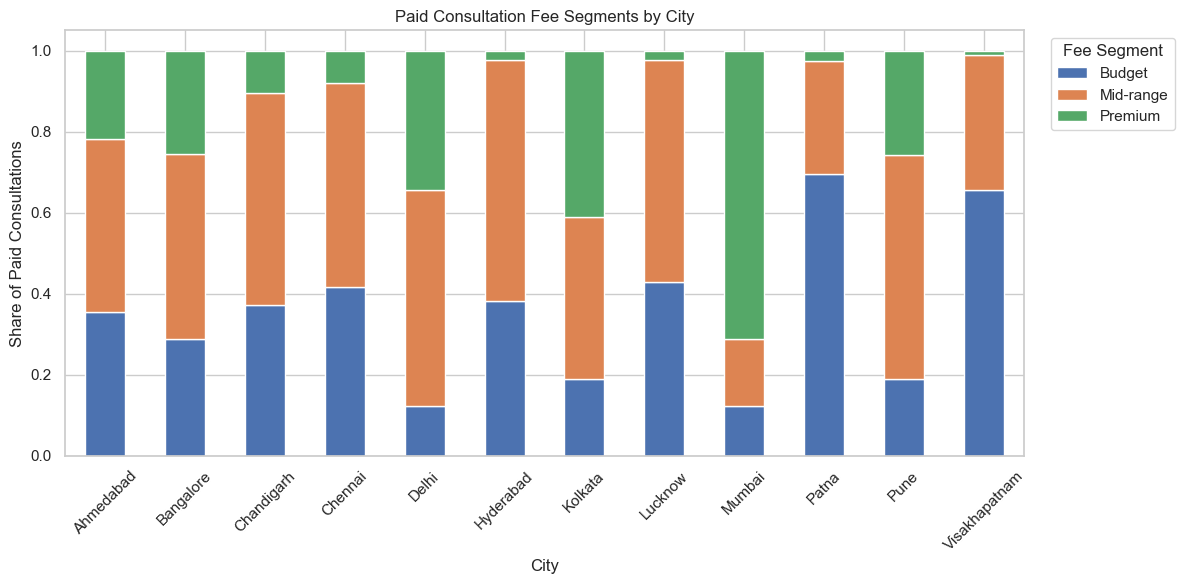

In [41]:
city_segment_share = city_segment.div(
    city_segment.sum(axis=1),
    axis=0
)

city_segment_share.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Paid Consultation Fee Segments by City")
plt.xlabel("City")
plt.ylabel("Share of Paid Consultations")
plt.xticks(rotation=45)
plt.legend(title="Fee Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 12.2 Fee Segments by Specialization

In [42]:
spec_segment = pd.crosstab(
    df_paid["Specialization"],
    df_paid["Fee_Segment"]
)

spec_segment

Fee_Segment,Budget,Mid-range,Premium
Specialization,,,
Cardiologist,11,67,39
Dentist,108,7,2
Dermatologist,32,65,21
ENT,43,53,22
General Physician,34,63,22
General Surgeon,36,53,27
Gynecologist,42,56,18
Neurologist,19,50,44
Orthopedist,41,53,25


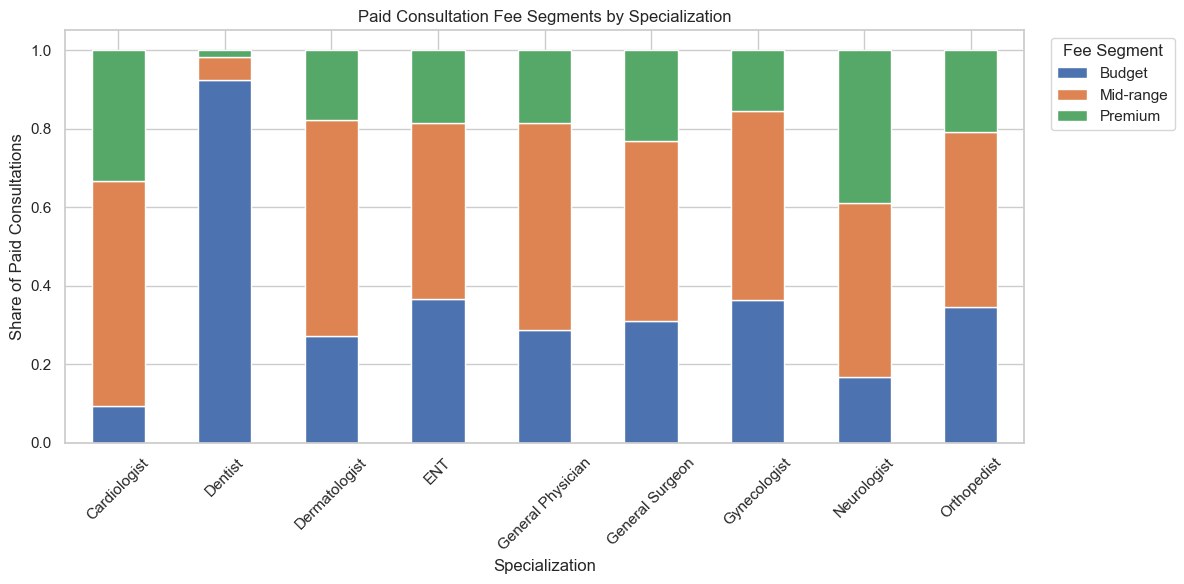

In [43]:
spec_segment_share = spec_segment.div(
    spec_segment.sum(axis=1),
    axis=0
)

spec_segment_share.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Paid Consultation Fee Segments by Specialization")
plt.xlabel("Specialization")
plt.ylabel("Share of Paid Consultations")
plt.xticks(rotation=45)
plt.legend(title="Fee Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 13. Consolidated EDA Findings

The following outputs are generated directly from the analysis so that the final summary remains consistent with the executed notebook.

In [44]:
highest_city = city_fee_stats.index[0]
lowest_city = city_fee_stats.index[-1]
highest_spec = spec_fee_stats.index[0]
lowest_spec = spec_fee_stats.index[-1]
highest_premium_city = premium_city.index[0]
highest_premium_spec = premium_spec.index[0]

print("EDA SUMMARY")
print("=" * 60)
print(f"1. Highest average-fee city: {highest_city} (₹{city_fee_stats.iloc[0]['Average_Fee']:,.0f})")
print(f"2. Lowest average-fee city: {lowest_city} (₹{city_fee_stats.iloc[-1]['Average_Fee']:,.0f})")
print(f"3. Highest average-fee specialization: {highest_spec} (₹{spec_fee_stats.iloc[0]['Average_Fee']:,.0f})")
print(f"4. Lowest average-fee specialization: {lowest_spec} (₹{spec_fee_stats.iloc[-1]['Average_Fee']:,.0f})")
print(f"5. Experience–fee Pearson correlation: {experience_fee_corr:.3f}")
print(f"6. Rating–fee Pearson correlation: {rating_fee_corr:.3f}")
print(f"7. Highest premium-fee share by city: {highest_premium_city}")
print(f"8. Highest premium-fee share by specialization: {highest_premium_spec}")

EDA SUMMARY
1. Highest average-fee city: Mumbai (₹1,479)
2. Lowest average-fee city: Patna (₹515)
3. Highest average-fee specialization: Cardiologist (₹1,016)
4. Lowest average-fee specialization: Dentist (₹425)
5. Experience–fee Pearson correlation: 0.142
6. Rating–fee Pearson correlation: -0.133
7. Highest premium-fee share by city: Mumbai
8. Highest premium-fee share by specialization: Neurologist


### Business-oriented takeaways

- Consultation pricing varies across cities and medical specializations.
- Metro and non-metro markets show different observed pricing levels in the dataset.
- Experience and patient rating have relatively weak linear relationships with consultation fee.
- City × specialization analysis reveals localized pricing differences for the same medical service.
- Premium-fee observations are not distributed uniformly across cities or specializations.
- Relative fee segmentation provides a simple way to distinguish lower-, middle-, and higher-priced paid consultations.

### Scope limitation

This dataset is observational and represents the collected Practo records used in the project. The analysis identifies patterns in the sample; it does not establish causal drivers of consultation pricing or represent the entire healthcare market.

## 14. Final Validation

Before completing the notebook, verify that the analysis dataset remains intact and that the main derived views were created successfully.

In [45]:
expected_columns = [
    "Doctor_Name",
    "Specialization",
    "Experience",
    "Hospital_Name",
    "City",
    "City_Tier",
    "Patient_Rating(%)",
    "Source",
    "Consultation_Fee(₹)"
]

assert list(df.columns) == expected_columns
assert len(df) == 1080
assert df.isna().sum().sum() == 0
assert df.duplicated().sum() == 0

assert "Fee_Segment" in df_paid.columns
assert premium_threshold >= 0
assert len(city_spec_pivot) == df["City"].nunique()
assert len(city_spec_pivot.columns) == df["Specialization"].nunique()

print("Final validation passed.")
print(f"Canonical dataset: {len(df):,} rows × {df.shape[1]} columns")
print("Missing values: 0")
print("Duplicate rows: 0")
print("EDA derived views: OK")

Final validation passed.
Canonical dataset: 1,080 rows × 9 columns
Missing values: 0
Duplicate rows: 0
EDA derived views: OK


## 15. Conclusion

This notebook completes the exploratory analysis stage of the Practo Doctor Consultation Fee Analysis project.

**Next project stage:** consolidate the findings into the project documentation and presentation, ensuring that every claim is supported by the executed analysis.